# Clasificar muestras: ¿cambia algo la correccion composicional?

## De que va esta libreta

En la libreta anterior transformamos una tabla de microbioma con la cadena composicional.
Ahora toca la pregunta practica: **¿sirve de algo?**

Vamos a intentar adivinar a que grupo pertenece cada muestra, dos veces:

- con la tabla **sin corregir** (abundancia relativa)
- con la tabla **corregida** (CLR)

Y comparamos. Como los datos los generamos nosotros, al final podremos comprobar algo que
con datos reales es imposible: si el modelo se fijo en los taxones correctos.

## Como seguirla

Igual que la anterior: celdas cortas, una idea por celda, y el codigo de las figuras en
`course_plots.py`. Se puede seguir sin haber hecho la libreta 09, porque volvemos a generar
los mismos datos.

## Curso de Invierno — Microbioma de la rizósfera
### Instructor: Rafael Pérez-Estrada

⏱ **Duración estimada: ~40 min** (parte 2 de 3 del capítulo *Transformación composicional*)

**Cómo usar este notebook:** todas las celdas ya vienen escritas: ejecútalas en orden, siguiendo al instructor. Empieza por la celda **🔧 Setup**, que prepara el entorno igual en Google Colab y en tu computadora.  
Si te atrasas, ejecuta todas las celdas hasta donde vamos (en Colab: *Entorno de ejecución → Ejecutar anteriores*).

---

## 🔧 Setup (~2 min)

Prepara el código de apoyo del capítulo (las funciones de la cadena composicional y de las figuras). Esta libreta genera sus propios datos, así que no descarga nada más.

In [1]:
# Detección de entorno (VSCode local vs Google Colab) y preparación del código de apoyo
import os, sys, shutil, zipfile, urllib.request
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
LESSON = 'composicional'
NECESITA_DATOS = False   # esta libreta genera sus propios datos

# Archivos del repositorio (rama main)
RAMA = 'main'
REPO_URL = f'https://github.com/MicroAgroBiome/Curso_Invierno_2026/raw/{RAMA}/'
MODULOS = ['__init__', 'compositional', 'course_plots', 'simulation', 'batch']

if IN_COLAB:
    BASE = Path('/content')
else:
    # Local: sube hasta encontrar la carpeta datos/ (repo clonado); si no existe, usa la carpeta actual
    BASE = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'datos').is_dir()), Path.cwd())

DATA_PATH = BASE / 'datos'
MODULE_PATH = BASE / 'src' / 'microagro_coda'
RESULTS_PATH = BASE / 'resultados' / LESSON

# Código de apoyo: en el repo ya está en src/; en Colab (o con el notebook suelto) se descarga
if not (MODULE_PATH / 'compositional.py').exists():
    MODULE_PATH.mkdir(parents=True, exist_ok=True)
    print("Descargando el código de apoyo...")
    for modulo in MODULOS:
        urllib.request.urlretrieve(f'{REPO_URL}src/microagro_coda/{modulo}.py', MODULE_PATH / f'{modulo}.py')
sys.path.insert(0, str(BASE / 'src'))

# Carpeta de trabajo: aquí quedan los resultados y, si hacen falta, los datos
PROCESSED_PATH = RESULTS_PATH / 'data' / 'processed'
PROCESSED_PATH.mkdir(parents=True, exist_ok=True)


def traer(nombre):
    """Ruta local de datos/<nombre>: usa la del repo o la descarga."""
    ruta = DATA_PATH / nombre
    if not ruta.exists():
        DATA_PATH.mkdir(parents=True, exist_ok=True)
        print(f"Descargando {nombre}...")
        urllib.request.urlretrieve(f'{REPO_URL}datos/{nombre}', ruta)
    return ruta


if NECESITA_DATOS:
    if not (PROCESSED_PATH / 'genus-counts-matrix.csv').exists():
        with zipfile.ZipFile(traer('composicional.zip')) as zf:
            for miembro in zf.namelist():
                if not miembro.endswith('/'):
                    (PROCESSED_PATH / Path(miembro).name).write_bytes(zf.read(miembro))
    shutil.copy(traer('subset_proyecto.zip'), RESULTS_PATH / 'data' / 'subset_proyecto.zip')

# El resto del notebook trabaja desde la carpeta de resultados
os.chdir(RESULTS_PATH)

print(f"Entorno: {'Google Colab' if IN_COLAB else 'Local (VSCode)'}")
print(f"Carpeta de trabajo: {os.path.relpath(RESULTS_PATH, BASE)}")

Entorno: Local (VSCode)
Carpeta de trabajo: resultados\composicional


## 1. Preparacion

In [2]:
from pathlib import Path
import sys

RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))

Las herramientas de siempre, mas tres cosas de scikit-learn que explicaremos cuando toque.

In [3]:
import numpy as np
import pandas as pd

from microagro_coda import compositional as comp
from microagro_coda import course_plots as figuras
from microagro_coda import simulation as sim

figuras.preparar_libreta()

In [4]:
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [5]:
UMBRAL_DE_PREVALENCIA = 0.70
SEMILLA = 42

## 2. Los datos y las dos versiones de la tabla

Generamos los mismos datos de la libreta anterior.

In [6]:
datos = sim.simulate_microbiome(sim.SimulationConfig(random_state=SEMILLA))

conteos = datos.counts
etiquetas = datos.labels
clases = sorted(etiquetas.unique())

Y ahora los cuatro pasos de la libreta 09, que `compositional_chain` hace de una vez.
Nos interesan dos de sus resultados.

In [7]:
relativa = conteos.div(conteos.sum(axis=1), axis=0)
cadena = comp.compositional_chain(relativa, min_prevalence=UMBRAL_DE_PREVALENCIA)

sin_clr = cadena["amalgamated"]   # abundancia relativa, sin corregir
con_clr = cadena["clr"]           # la misma tabla tras el CLR

Es importante que las dos tengan **las mismas columnas y las mismas filas**. Asi lo unico
que las diferencia es la transformacion, y la comparacion es justa.

In [8]:
sin_clr.shape == con_clr.shape

True

Asi se ven los mismos cinco numeros en una y en otra.

In [9]:
sin_clr.iloc[:2, :4].round(5)

,Taxon-000,Taxon-001,Taxon-002,Taxon-003
sample,,,,
S0000,0.00032,0.03944,0.03569,0.16455
S0001,0.43947,0.10755,0.00914,0.04828


In [10]:
con_clr.iloc[:2, :4].round(3)

,Taxon-000,Taxon-001,Taxon-002,Taxon-003
sample,,,,
S0000,1.295,6.115,6.015,7.543
S0001,9.787,8.380,5.914,7.579


## 3. Primera mirada: el ACP

Antes de clasificar conviene **mirar** los datos. El analisis de componentes principales
(ACP) resume cientos de columnas en dos, quedandose con las direcciones donde las muestras
mas se diferencian.

Lo importante: **el ACP no ve las etiquetas**. Si aun asi los grupos aparecen separados, es
que la diferencia esta de verdad en los datos.

Hacemos lo mismo con las dos tablas. Primero escalamos (dejar cada columna con media 0 y
desviacion 1) para que ningun taxon pese mas solo por tener numeros mas grandes.

In [11]:
def calcular_acp(tabla):
    """Escala la tabla, calcula el ACP y devuelve los puntos y la varianza explicada."""
    escalada = StandardScaler().fit_transform(tabla)
    modelo = PCA(n_components=2, random_state=SEMILLA)
    puntos = modelo.fit_transform(escalada)
    puntos = pd.DataFrame(puntos, index=tabla.index, columns=["PC1", "PC2"])
    return puntos, modelo.explained_variance_ratio_

In [12]:
puntos_sin_clr, varianza_sin_clr = calcular_acp(sin_clr)
puntos_con_clr, varianza_con_clr = calcular_acp(con_clr)

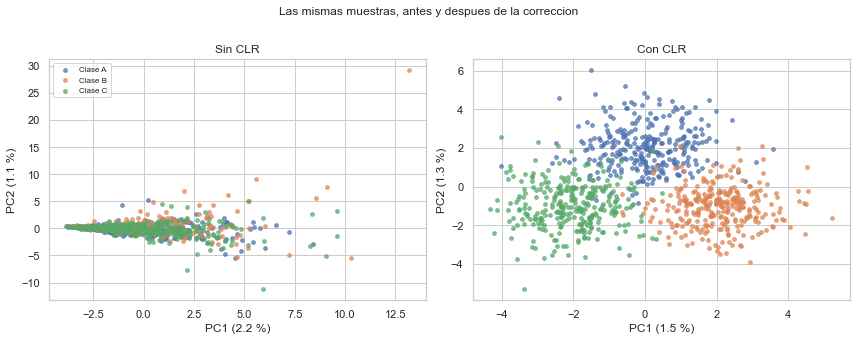

In [13]:
#| label: fig-l3-acp-simulado
#| code-fold: true
#| code-summary: "Ver el código de la gráfica"
#| fig-cap: "ACP de los mismos datos simulados sin CLR (izquierda) y con CLR (derecha), coloreado por clase."
figura = figuras.comparar_acp(
    puntos_sin_clr, puntos_con_clr, etiquetas, varianza_sin_clr, varianza_con_clr
)

A la izquierda los tres grupos estan completamente mezclados. A la derecha se separan.

Son **los mismos datos**: lo unico que cambia es la transformacion.

## 4. Ahora si, clasificar

Vamos a usar un modelo muy sencillo de explicar: **k vecinos mas cercanos**. Para adivinar
el grupo de una muestra, busca las 15 muestras que mas se le parecen y se queda con el
grupo mas comun entre ellas.

Lo elegimos a proposito porque trabaja con **distancias**, que es justo lo que la
correccion composicional arregla.

### Como se mide si acierta

No vale entrenar y evaluar con las mismas muestras: el modelo se las sabria de memoria.
Usamos **validacion cruzada**: partimos las muestras en 5 grupos, entrenamos con 4 y
predecimos el quinto, y repetimos cambiando cual queda fuera. Asi cada muestra se predice
con un modelo que no la vio.

In [14]:
particion = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

Definimos una funcion que entrena y devuelve las predicciones. El `make_pipeline` encadena
el escalado y el modelo, para que el escalado se calcule **dentro** de cada reparto y no
con todas las muestras a la vez.

In [15]:
def predecir(tabla, modelo):
    """Devuelve la prediccion de cada muestra, hecha sin que el modelo la haya visto."""
    flujo = make_pipeline(StandardScaler(), modelo)
    predicciones = cross_val_predict(flujo, tabla, etiquetas, cv=particion)
    return pd.Series(predicciones, index=tabla.index)

Y otra que cuenta cuantas acerto. Usamos la **exactitud balanceada**: el promedio de
aciertos en cada grupo por separado. Con tres grupos, acertar al azar da 0.33.

In [16]:
from sklearn.metrics import balanced_accuracy_score

def aciertos(predicciones):
    return balanced_accuracy_score(etiquetas, predicciones)

Probemos con la tabla **sin corregir**.

In [17]:
#| label: l3-knn-sin-clr
vecinos = KNeighborsClassifier(n_neighbors=15)

predicciones_sin_clr = predecir(sin_clr, vecinos)
aciertos(predicciones_sin_clr)

0.36222222222222217

0.36, y el azar es 0.33. El modelo no esta aprendiendo practicamente nada.

Ahora con la tabla **corregida**.

In [18]:
#| label: l3-knn-con-clr
predicciones_con_clr = predecir(con_clr, vecinos)
aciertos(predicciones_con_clr)

0.8333333333333334

De 0.36 a 0.83. **Los mismos datos, el mismo modelo, la misma validacion.**

### Donde se equivoca

La matriz de confusion cruza lo que era cada muestra con lo que el modelo dijo. La diagonal
son los aciertos.

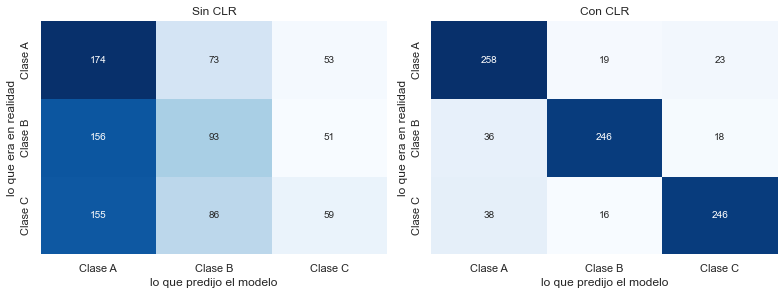

In [19]:
#| label: fig-l3-confusion
#| code-fold: true
#| code-summary: "Ver el código de la gráfica"
#| fig-cap: "Matrices de confusión de 15 vecinos más cercanos sin CLR y con CLR."
figura = figuras.comparar_matrices_de_confusion(
    etiquetas, predicciones_sin_clr, predicciones_con_clr, clases
)

Sin CLR las predicciones se reparten por todas partes. Con CLR la diagonal concentra casi
todo.

## 5. ¿Pasa lo mismo con otros modelos?

Conviene no sacar conclusiones de un solo modelo. Probamos dos mas:

- **Regresion logistica**: traza fronteras rectas entre los grupos.
- **Bosque aleatorio**: hace muchas preguntas del tipo "¿este taxon esta por encima de tal
  valor?" y vota.

In [20]:
modelos = {
    "15 vecinos": KNeighborsClassifier(n_neighbors=15),
    "Regresion logistica": LogisticRegression(max_iter=3000, random_state=SEMILLA),
    "Bosque aleatorio": RandomForestClassifier(n_estimators=300, random_state=SEMILLA),
}

tablas = {"Sin CLR": sin_clr, "Con CLR": con_clr}

Recorremos las seis combinaciones. Tarda un poco.

In [21]:
filas = []

for nombre_modelo, modelo in modelos.items():
    for nombre_tabla, tabla in tablas.items():
        resultado = aciertos(predecir(tabla, modelo))
        filas.append({
            "modelo": nombre_modelo,
            "representacion": nombre_tabla,
            "aciertos": round(resultado, 3),
        })

resultados = pd.DataFrame(filas)

In [22]:
#| label: tbl-l3-modelos
#| tbl-cap: "Exactitud balanceada por validación cruzada de tres modelos, sin y con CLR (azar = 0.33)."
resultados.pivot(index="modelo", columns="representacion", values="aciertos")

representacion,Con CLR,Sin CLR
modelo,,
15 vecinos,0.833,0.362
Bosque aleatorio,0.959,0.949
Regresion logistica,0.940,0.618


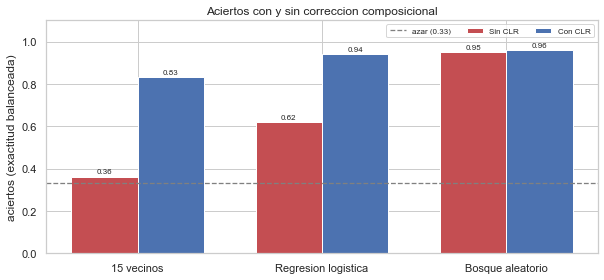

In [23]:
#| label: fig-l3-aciertos
#| code-fold: true
#| code-summary: "Ver el código de la gráfica"
#| fig-cap: "Exactitud balanceada de los tres modelos sin y con CLR; la línea marca el azar."
figura = figuras.comparar_aciertos(resultados, azar=1 / len(clases))

### Como leer esto

Tres resultados distintos, y los tres tienen explicacion:

- **Los vecinos** son los que mas ganan. Comparan muestras por distancia y no pueden
  compensar nada: si el espacio esta deformado, fallan.
- **La regresion logistica** se recupera bastante sin CLR. Puede sumar y restar columnas
  entre si, y asi cancelar parte de la deformacion.
- **El bosque aleatorio** casi no nota la diferencia. Mira cada columna por separado con
  umbrales, y eso le afecta poco.

> La moraleja no es "el CLR siempre mejora", sino **que depende del metodo**. Si usas
> distancias, agrupamientos u ordenaciones como el ACP, la correccion es imprescindible.

## 6. ¿Se fijo en los taxones correctos?

Esta es la ventaja de trabajar con datos inventados: sabemos cuales son los taxones que de
verdad distinguen a los grupos. Los llamamos **taxones firma**.

In [24]:
taxones_firma = datos.signature_taxa
len(taxones_firma)

30

De los 30, algunos eran raros y se fueron a `other-genera` al amalgamar. Veamos cuantos
quedan disponibles.

In [25]:
disponibles = [taxon for taxon in taxones_firma if taxon in con_clr.columns]
len(disponibles)

21

Entrenamos una regresion logistica con todas las muestras y miramos que peso le da a cada
taxon. Cuanto mas grande el coeficiente, mas se apoya en el.

In [26]:
def pesos_del_modelo(tabla):
    """Entrena una regresion logistica y devuelve el peso de cada taxon."""
    modelo = LogisticRegression(max_iter=3000, random_state=SEMILLA)
    modelo.fit(StandardScaler().fit_transform(tabla), etiquetas)
    pesos = np.abs(modelo.coef_).mean(axis=0)
    return pd.Series(pesos, index=tabla.columns)

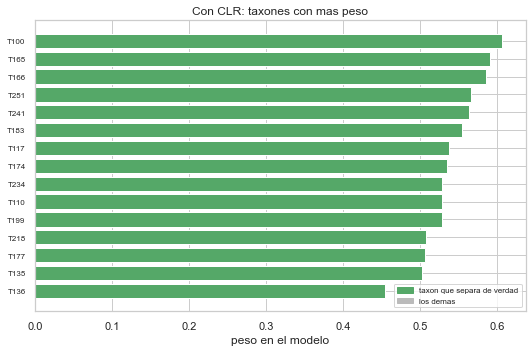

In [27]:
#| label: fig-l3-pesos-con-clr
#| code-fold: true
#| code-summary: "Ver el código de la gráfica"
#| fig-cap: "Con CLR: taxones con más peso en la regresión logística; los taxones firma están resaltados."
pesos_con_clr = pesos_del_modelo(con_clr)
figura = figuras.taxones_mas_importantes(
    pesos_con_clr, taxones_firma, titulo="Con CLR: taxones con mas peso"
)

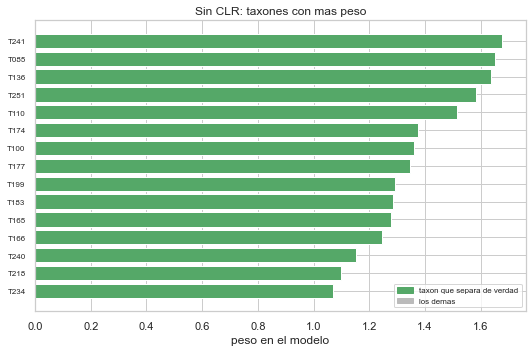

In [28]:
#| label: fig-l3-pesos-sin-clr
#| code-fold: true
#| code-summary: "Ver el código de la gráfica"
#| fig-cap: "Sin CLR: taxones con más peso en la regresión logística; los taxones firma están resaltados."
pesos_sin_clr = pesos_del_modelo(sin_clr)
figura = figuras.taxones_mas_importantes(
    pesos_sin_clr, taxones_firma, titulo="Sin CLR: taxones con mas peso"
)

Contemos cuantos de los 15 primeros son firma de verdad, en cada caso.

In [29]:
def cuantos_aciertos_en_los_primeros(pesos, cuantos=15):
    primeros = pesos.nlargest(cuantos).index
    return sum(1 for taxon in primeros if taxon in taxones_firma)

In [30]:
#| label: l3-firma
print("Con CLR:", cuantos_aciertos_en_los_primeros(pesos_con_clr), "de 15")
print("Sin CLR:", cuantos_aciertos_en_los_primeros(pesos_sin_clr), "de 15")

Con CLR: 15 de 15
Sin CLR: 15 de 15


Los dos encuentran los taxones correctos, aunque sin CLR el modelo apenas acierte las
clases. No es contradictorio, y conviene entender por que:

La regresion logistica **ve las etiquetas mientras aprende**. Con 900 muestras, encuentra
que columnas se relacionan con el grupo aunque el espacio este deformado. El ACP de la
seccion 3, en cambio, **no las ve**, y por eso ahi la diferencia era total.

> Dicho de otra forma: **la correccion composicional importa mas cuanta menos ayuda tenga
> el metodo**. Imprescindible para explorar y para medir distancias; util pero no decisiva
> para un modelo supervisado con muchos datos.

## 7. Resumen

| | sin CLR | con CLR |
|---|---|---|
| Los grupos se ven separados en el ACP | no | si |
| Aciertos con 15 vecinos | 0.36 (azar: 0.33) | 0.83 |
| Aciertos con regresion logistica | 0.62 | 0.94 |
| Aciertos con bosque aleatorio | 0.95 | 0.96 |

Tres ideas para quedarse:

1. **Los datos de microbioma son proporciones**, y eso deforma las distancias entre
   muestras. No es un detalle teorico: cambia los resultados.
2. **La correccion no inventa senal**, la destapa. La diferencia entre grupos estaba ahi
   desde el principio; sin corregir, quedaba escondida.
3. **Cuanto menos supervisado sea el metodo, mas importa.** Un ACP o un agrupamiento sin
   corregir puede llevar a conclusiones falsas con mucha facilidad.